# 06a · First prediction: will this flight be late or cancelled?

**The question.** For every flight, **2 hours before its scheduled departure**: will it leave more than 15 minutes late, or be cancelled?

**The use.** The agency warns clients on the risky flights and checks their connections (decision cards, notebook 07).

**How we test honestly**
- We split by **time**: *fit* = January to June, *valid* = July to September, and the final **test = October to December**.
- We train on fit, compare and tune models on valid, then train again on January to September with the chosen settings. The test months are opened **only once, in the last section**, after a marker cell. An automatic check enforces this.
- Every model must beat a **dumb answer**.

**Which score?** Accuracy alone is not allowed: since about 1 flight in 5 is late, "nobody is ever late" is already about 80% accurate and useless. A **missed** late flight (a client who is not warned) is worse than a **needless** warning (one extra message). So we use:
- **PR-AUC** (precision-recall area): how well the model ranks late flights above on-time ones. The dumb answer scores the share of late flights.
- **Precision, recall and F1 at the cut-off "warn the riskiest 20% of flights"**: *precision* = of the flights we warn about, how many really are late; *recall* = of all late flights, how many we warn about. Twenty percent is a placeholder for what the agency can handle; notebook 07 fixes the real cut-off.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from src import common, viz

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import torch
import torch.nn as nn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

common.require_processed("features.parquet", "destination_groups.parquet")
viz.apply_style()
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
pd.set_option("display.width", 170)
CAPACITY = 0.20          # placeholder: warn the riskiest 20% of flights

In [2]:
features = pd.read_parquet(common.PROC / "features.parquet")
dev = features[features["part"].isin(["fit", "valid"])].reset_index(drop=True)
del features   # from here until the final section, only the training months are in memory
dev_tune = dev.assign(dest_group=dev["dest_group_fit"])      # tuning stage: destination groups built from January-June only, so no valid-month outcome leaks into the comparison
fit, valid = dev_tune[dev_tune["part"] == "fit"], dev_tune[dev_tune["part"] == "valid"]
y_fit, y_valid, y_dev = fit["late_or_cancelled"].to_numpy(), valid["late_or_cancelled"].to_numpy(), dev["late_or_cancelled"].to_numpy()
print(f"fit (Jan-Jun): {len(fit):,} flights, {y_fit.mean():.1%} late or cancelled | valid (Jul-Sep): {len(valid):,}, {y_valid.mean():.1%}")

fit (Jan-Jun): 222,402 flights, 24.1% late or cancelled | valid (Jul-Sep): 108,481, 29.1%


## 1. Columns removed because they give the answer away (leakage)
The model may only use what is known 2 hours before departure (notebook 05). These columns exist in the data but are **never** inputs. They are saved in `reports/06_leakage_removed.csv`.

In [3]:
LEAKAGE = [
    ("dep_time", "The actual departure time: only known when the flight leaves. A missing value even means 'cancelled'."),
    ("dep_delay", "The actual departure delay: it is the answer itself (late means more than 15 minutes)."),
    ("arr_time", "The actual arrival time: known after the flight lands; a missing value also reveals a cancelled or diverted flight."),
    ("arr_delay", "The actual arrival delay: known after landing, and strongly tied to the departure delay."),
    ("air_time", "Minutes spent in the air: known only after the flight; missing for cancelled flights."),
    ("cancelled", "Built from the missing departure time: it is part of the answer."),
    ("diverted", "Built from the missing arrival time: only known after the flight."),
    ("late_or_cancelled", "The target itself."),
    ("weather at the scheduled departure hour", "It is 2 hours in the future at prediction time. We use the reading from 2 hours earlier instead."),
    ("earlier flight's delay when it had not yet left", "Not known yet 2 hours before: the column is left empty in that case (`prev_known = 0`)."),
    ("an empty plane (no tail number)", "Every flight without a tail number was cancelled, so empty plane columns would reveal the answer. Those flights get the typical plane in notebook 05."),
]
common.REPORTS.mkdir(parents=True, exist_ok=True)
pd.DataFrame(LEAKAGE, columns=["column", "reason"]).to_csv(common.REPORTS / "06_leakage_removed.csv", index=False)
NUM = ["hour", "distance", "origin_hour_flights", "plane_age", "seats", "temp", "wind_speed", "wind_gust", "visib", "precip", "pressure",
       "prev_dep_delay", "weather_filled", "prev_known"]
CAT = ["carrier", "origin", "dest_group", "weekday"]
assert not ({c for c, _ in LEAKAGE} & set(NUM + CAT))
print(f"{len(NUM) + len(CAT)} input columns; {len(LEAKAGE)} columns or ideas removed as leakage")

18 input columns; 11 columns or ideas removed as leakage


## 2. The scores
A function that, given the real outcome and each flight's risk, returns the four scores. "Warn the riskiest 20%" means: rank flights by risk and take the top fifth. Ties are broken at random with a fixed seed.

In [4]:
def scores(y, risk, share=CAPACITY):
    rng = np.random.default_rng(common.SEED)
    k = int(round(len(y) * share))
    order = np.argsort(-(np.asarray(risk, dtype=float) + rng.random(len(y)) * 1e-9), kind="stable")
    flagged = np.zeros(len(y), dtype=bool)
    flagged[order[:k]] = True
    hits = int((flagged & (y == 1)).sum())
    precision, recall = hits / k, hits / y.sum()
    f1 = 2 * precision * recall / (precision + recall) if hits else 0.0
    return {"pr_auc": average_precision_score(y, risk), "precision_at_20pct": precision, "recall_at_20pct": recall, "f1_at_20pct": f1}

def dumb_scores(y):
    return {"pr_auc": y.mean(), "precision_at_20pct": 0.0, "recall_at_20pct": 0.0, "f1_at_20pct": 0.0}   # flags nobody; PR-AUC of no information = share of late flights

## 3. Dumb answers every model must beat
1. **"Nobody is late"**: flags no flight. Its PR-AUC equals the share of late flights.
2. **"Hour-of-day rule"**: each flight's risk is the late rate of its scheduled hour in the training months. It shows what the models add beyond the obvious ("evening flights are later").

In [5]:
def make_hour_rule(train):
    rate = train.groupby("hour")["late_or_cancelled"].mean()
    overall = train["late_or_cancelled"].mean()
    return lambda d: d["hour"].map(rate).fillna(overall).to_numpy()

risk_fns_fit = {"hour_rule": make_hour_rule(fit)}
valid_scores = {"dumb_never_late": dumb_scores(y_valid), "hour_rule": scores(y_valid, risk_fns_fit["hour_rule"](valid))}
print(pd.DataFrame(valid_scores).T.round(3).to_string())

                 pr_auc  precision_at_20pct  recall_at_20pct  f1_at_20pct
dumb_never_late   0.291               0.000             0.00        0.000
hour_rule         0.408               0.451             0.31        0.367


## 4. Three models
All three see the same input columns. Numbers with gaps get a median fill plus a "was missing" flag, are scaled, and categories (airline, airport, destination type, weekday) are one-hot encoded; gradient boosting reads missing values and categories natively.

1. **Logistic regression**: a simple, readable model that adds up weighted evidence. Tuned: how strongly to regularise (`C`).
2. **Gradient boosting** (`HistGradientBoostingClassifier`): many small decision trees, each correcting the previous ones; usually the strongest on tables. Tuned: learning rate and tree size.
3. **Neural network** (PyTorch): two small hidden layers (64 and 32 units). Trained until the score on the valid months stops improving for 3 rounds, with fixed seeds, on the CPU.

**Tuning uses the valid months only (July to September)**, and the destination-type column used while comparing is the January-to-June version (see notebook 05), so those months' outcomes cannot leak into it. July to September were stormy (29% late), unlike the test months (14%), so we compare models by how well they **rank** flights (PR-AUC), and we never pick a cut-off on valid.

In [6]:
def make_prep():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

CATEGORIES = {c: sorted(dev[c].unique()) for c in CAT}   # the vocabulary seen in training
def as_categorical(d):
    out = d[NUM + CAT].copy()
    for c in CAT:
        out[c] = pd.Categorical(out[c], categories=CATEGORIES[c])
    return out

def lr_model(C):
    return Pipeline([("prep", make_prep()), ("lr", LogisticRegression(C=C, max_iter=2000, random_state=common.SEED))])

def hgb_model(lr, leaves):
    return HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, max_iter=200, l2_regularization=1.0,
                                          categorical_features="from_dtype", early_stopping=False, random_state=common.SEED)

**Logistic regression: which `C`?**

In [7]:
lr_tuning = {}
for C in [0.01, 0.1, 1, 10]:
    pipe = lr_model(C).fit(fit[NUM + CAT], y_fit)
    lr_tuning[C] = (average_precision_score(y_valid, pipe.predict_proba(valid[NUM + CAT])[:, 1]), pipe)
best_C = max(lr_tuning, key=lambda c: lr_tuning[c][0])
print({c: round(v[0], 4) for c, v in lr_tuning.items()}, "-> best C =", best_C)
lr_fit = lr_tuning[best_C][1]
risk_fns_fit["logistic_regression"] = lambda d: lr_fit.predict_proba(d[NUM + CAT])[:, 1]

{0.01: 0.5229, 0.1: 0.5228, 1: 0.5227, 10: 0.5225} -> best C = 0.01


**Gradient boosting: which learning rate and tree size?**

In [8]:
hgb_tuning = {}
X_fit_cat, X_valid_cat = as_categorical(fit), as_categorical(valid)
for lr in [0.05, 0.1]:
    for leaves in [15, 31, 63]:
        m = hgb_model(lr, leaves).fit(X_fit_cat, y_fit)
        hgb_tuning[(lr, leaves)] = (average_precision_score(y_valid, m.predict_proba(X_valid_cat)[:, 1]), m)
best_hgb = max(hgb_tuning, key=lambda k: hgb_tuning[k][0])
print({k: round(v[0], 4) for k, v in hgb_tuning.items()}, "\n-> best (learning rate, leaves) =", best_hgb)
hgb_fit = hgb_tuning[best_hgb][1]
risk_fns_fit["gradient_boosting"] = lambda d: hgb_fit.predict_proba(as_categorical(d))[:, 1]

{(0.05, 15): 0.5172, (0.05, 31): 0.5178, (0.05, 63): 0.509, (0.1, 15): 0.5209, (0.1, 31): 0.5116, (0.1, 63): 0.5073} 
-> best (learning rate, leaves) = (0.1, 15)


**Neural network.** The input is the same prepared matrix as for logistic regression.

In [9]:
def new_net(width):
    return nn.Sequential(nn.Linear(width, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 1))

def net_risk(net, X):
    net.eval()
    with torch.no_grad():
        return torch.sigmoid(net(torch.tensor(X, dtype=torch.float32)).squeeze(1)).numpy()

def train_net(X, y, X_val=None, y_val=None, max_epochs=30, patience=3, fixed_epochs=None):
    """Train with Adam. With validation data: stop when it stops improving, return the best epoch. Otherwise train `fixed_epochs`."""
    torch.manual_seed(common.SEED)
    gen = torch.Generator().manual_seed(common.SEED)
    net = new_net(X.shape[1])
    opt, loss_fn = torch.optim.Adam(net.parameters(), lr=1e-3), nn.BCEWithLogitsLoss()
    Xt, yt = torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)
    best_score, best_state, best_epoch, waited = -1.0, None, 0, 0
    for epoch in range(1, (fixed_epochs or max_epochs) + 1):
        net.train()
        order = torch.randperm(len(Xt), generator=gen)
        for i in range(0, len(order), 2048):
            idx = order[i:i + 2048]
            opt.zero_grad()
            loss_fn(net(Xt[idx]).squeeze(1), yt[idx]).backward()
            opt.step()
        if X_val is not None:
            score = average_precision_score(y_val, net_risk(net, X_val))
            if score > best_score:
                best_score, best_state, best_epoch, waited = score, copy.deepcopy(net.state_dict()), epoch, 0
            else:
                waited += 1
                if waited >= patience:
                    break
    if X_val is not None:
        net.load_state_dict(best_state)
        return net, best_epoch, best_score
    return net, fixed_epochs, None

prep_fit = make_prep().fit(fit[NUM + CAT])
net_fit, best_epoch, net_valid_score = train_net(prep_fit.transform(fit[NUM + CAT]), y_fit, prep_fit.transform(valid[NUM + CAT]), y_valid)
print(f"neural network: best epoch {best_epoch}, valid PR-AUC {net_valid_score:.4f}")
risk_fns_fit["neural_network"] = lambda d: net_risk(net_fit, prep_fit.transform(d[NUM + CAT]))

neural network: best epoch 2, valid PR-AUC 0.5321


## 5. Compare on the valid months
The best of the three by PR-AUC on valid is the one we carry forward. (Scores on valid are for choosing only; the honest scores come in the last section.)

In [10]:
for name in ["logistic_regression", "gradient_boosting", "neural_network"]:
    valid_scores[name] = scores(y_valid, risk_fns_fit[name](valid))
valid_table = pd.DataFrame(valid_scores).T
valid_table.round(4).rename_axis("model").reset_index().melt(id_vars="model", var_name="metric", value_name="value").to_csv(common.REPORTS / "06a_valid_results.csv", index=False)
print(valid_table.round(3).to_string())
real_models = ["logistic_regression", "gradient_boosting", "neural_network"]
best_model = max(real_models, key=lambda m: valid_scores[m]["pr_auc"])
print("\nbest model on valid:", best_model)

                     pr_auc  precision_at_20pct  recall_at_20pct  f1_at_20pct
dumb_never_late       0.291               0.000            0.000        0.000
hour_rule             0.408               0.451            0.310        0.367
logistic_regression   0.523               0.555            0.381        0.452
gradient_boosting     0.521               0.554            0.381        0.451
neural_network        0.532               0.565            0.388        0.460

best model on valid: neural_network


**Weekly reach on the valid months.** We also measure, week by week, how many late flights the chosen model reaches when it warns the riskiest 20% of that week's flights. This weekly reach on the *valid* months sets the re-check line used in notebook 07 (setting it from the held-out months would make the line circular).

In [11]:
dates = pd.read_parquet(common.PROC / "flights_clean.parquet", columns=["row_id", "sched_dep_dt"]).set_index("row_id")["sched_dep_dt"]
week_of = valid["row_id"].map(dates).dt.to_period("W").dt.start_time.to_numpy()
risk_valid = risk_fns_fit[best_model](valid)
weekly_rows = []
for week in np.unique(week_of):
    pick = week_of == week
    weekly_rows.append(dict(week_start=pd.Timestamp(week).date(), n=int(pick.sum()), recall_at_20pct=round(scores(y_valid[pick], risk_valid[pick])["recall_at_20pct"], 4)))
valid_weekly = pd.DataFrame(weekly_rows)
valid_weekly.to_csv(common.REPORTS / "06a_valid_weekly_reach.csv", index=False)
print(valid_weekly.to_string(index=False))

week_start    n  recall_at_20pct
2023-06-26 2100           0.3578
2023-07-03 7876           0.3867
2023-07-10 8329           0.3567
2023-07-17 8334           0.3590
2023-07-24 8331           0.3508
2023-07-31 8322           0.4316
2023-08-07 8238           0.3669
2023-08-14 8273           0.3896
2023-08-21 8269           0.3670
2023-08-28 8153           0.3906
2023-09-04 8125           0.3271
2023-09-11 8272           0.3642
2023-09-18 8527           0.3975
2023-09-25 7332           0.4411


## 6. What does the best model rely on? (permutation importance)
We shuffle one column at a time on the valid months and see how much the PR-AUC drops. A big drop means the model relies on that column. This uses the model trained on January to June, on the valid months only.

In [12]:
def permutation_importance(risk_fn, frame, y, repeats=3):
    rng = np.random.default_rng(common.SEED)
    base = average_precision_score(y, risk_fn(frame))
    rows = []
    for col in NUM + CAT:
        drops = []
        for _ in range(repeats):
            shuffled = frame.copy()
            shuffled[col] = rng.permutation(shuffled[col].to_numpy())
            drops.append(base - average_precision_score(y, risk_fn(shuffled)))
        rows.append({"feature": col, "importance_mean": float(np.mean(drops)), "importance_std": float(np.std(drops))})
    return pd.DataFrame(rows).sort_values("importance_mean", ascending=False).reset_index(drop=True)

importance = permutation_importance(risk_fns_fit[best_model], valid[NUM + CAT], y_valid)
importance.round(4).to_csv(common.REPORTS / "06a_importance.csv", index=False)
print(importance.head(8).round(4).to_string(index=False))

       feature  importance_mean  importance_std
          hour           0.1188          0.0007
prev_dep_delay           0.0769          0.0003
       carrier           0.0265          0.0004
         visib           0.0125          0.0004
          temp           0.0114          0.0003
      pressure           0.0072          0.0004
        precip           0.0051          0.0005
    prev_known           0.0044          0.0003


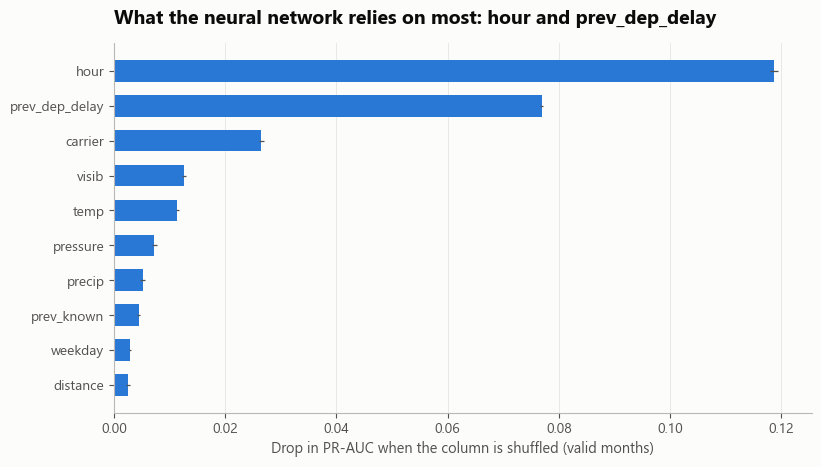

In [13]:
top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color=viz.BLUE, height=0.62, error_kw={"ecolor": viz.INK_2, "elinewidth": 0.9})
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_title(f"What the {best_model.replace('_', ' ')} relies on most: {importance.loc[0, 'feature']} and {importance.loc[1, 'feature']}")
ax.set_xlabel("Drop in PR-AUC when the column is shuffled (valid months)")
chart_importance = viz.save_figure(fig, "06a_importance.png")
plt.show()

## 7. Train again on January to September with the chosen settings
More recent data is more useful, so the final models are trained on fit **and** valid together (January to September), with the settings chosen above. Nothing about the test months has been used so far.

In [14]:
final_fns = {"hour_rule": make_hour_rule(dev)}
lr_final = lr_model(best_C).fit(dev[NUM + CAT], y_dev)
final_fns["logistic_regression"] = lambda d: lr_final.predict_proba(d[NUM + CAT])[:, 1]
hgb_final = hgb_model(*best_hgb).fit(as_categorical(dev), y_dev)
final_fns["gradient_boosting"] = lambda d: hgb_final.predict_proba(as_categorical(d))[:, 1]
prep_dev = make_prep().fit(dev[NUM + CAT])
net_final, _, _ = train_net(prep_dev.transform(dev[NUM + CAT]), y_dev, fixed_epochs=best_epoch)
final_fns["neural_network"] = lambda d: net_risk(net_final, prep_dev.transform(d[NUM + CAT]))
print("final models trained on", f"{len(dev):,}", "flights from January to September")

final models trained on 330,883 flights from January to September


## 8. FINAL TEST: October to December, opened once
From here on we look at the held-out months. We do **not** go back and change any model after seeing these numbers.

In [15]:
# ---- FINAL TEST (run once) ----
features = pd.read_parquet(common.PROC / "features.parquet")
held = features[~features["part"].isin(["fit", "valid"])].reset_index(drop=True)
y_held = held["late_or_cancelled"].to_numpy()
print(f"{len(held):,} flights held out; {y_held.mean():.1%} are late or cancelled")
risk_held = {name: fn(held) for name, fn in final_fns.items()}
test_scores = {"dumb_never_late": dumb_scores(y_held)}
test_scores.update({name: scores(y_held, risk) for name, risk in risk_held.items()})
test_table = pd.DataFrame(test_scores).T
test_table.round(4).rename_axis("model").reset_index().melt(id_vars="model", var_name="metric", value_name="value").to_csv(common.REPORTS / "06a_results.csv", index=False)
print(test_table.round(3).to_string())

104,469 flights held out; 14.1% are late or cancelled


                     pr_auc  precision_at_20pct  recall_at_20pct  f1_at_20pct
dumb_never_late       0.141               0.000            0.000        0.000
hour_rule             0.184               0.194            0.277        0.228
logistic_regression   0.282               0.274            0.390        0.322
gradient_boosting     0.294               0.289            0.412        0.340
neural_network        0.290               0.284            0.404        0.334


**Reading the test results.** The lines below are computed from the table above.

In [16]:
pr_test = test_table["pr_auc"]
three = ["logistic_regression", "gradient_boosting", "neural_network"]
spread = pr_test[three].max() - pr_test[three].min()
print(f"Every model beats both dumb answers: {all(pr_test[m] > pr_test['hour_rule'] for m in three)} (PR-AUC {pr_test[three].min():.2f} to {pr_test[three].max():.2f}, against {pr_test['dumb_never_late']:.2f} for 'nobody is late' and {pr_test['hour_rule']:.2f} for the hour-of-day rule).")
print(f"Warning the riskiest 20% of flights with the chosen model ({best_model}) reaches {test_table.loc[best_model, 'recall_at_20pct']:.0%} of all late or cancelled flights (random picking reaches 20%); {test_table.loc[best_model, 'precision_at_20pct']:.0%} of the flights warned about really are late ({y_held.mean():.0%} overall).")
print(f"The chosen model was the best on the valid months ({valid_scores[best_model]['pr_auc']:.3f}). On the held-out months the best is {pr_test[three].idxmax()} ({pr_test[three].max():.3f}). We keep the pre-chosen model: switching after seeing the test scores would make them dishonest.")
print(f"The three models differ by {spread:.3f} PR-AUC: {'practically equally good for our purpose' if spread < 0.02 else 'clearly different'}.")
print(f"Scores are lower than on valid ({valid_scores[best_model]['pr_auc']:.2f} against {pr_test[best_model]:.2f}) because the held-out months are calmer ({y_held.mean():.0%} late or cancelled against {y_valid.mean():.0%}): every score is harder to reach, so compare each model with the dumb answer of its own period.")

Every model beats both dumb answers: True (PR-AUC 0.28 to 0.29, against 0.14 for 'nobody is late' and 0.18 for the hour-of-day rule).
Warning the riskiest 20% of flights with the chosen model (neural_network) reaches 40% of all late or cancelled flights (random picking reaches 20%); 28% of the flights warned about really are late (14% overall).
The chosen model was the best on the valid months (0.532). On the held-out months the best is gradient_boosting (0.294). We keep the pre-chosen model: switching after seeing the test scores would make them dishonest.
The three models differ by 0.011 PR-AUC: practically equally good for our purpose.
Scores are lower than on valid (0.53 against 0.29) because the held-out months are calmer (14% late or cancelled against 29%): every score is harder to reach, so compare each model with the dumb answer of its own period.


The best model (chosen on valid, before this section) is now evaluated in detail.

In [17]:
best_risk = risk_held[best_model]
k = int(round(len(y_held) * CAPACITY))
rng = np.random.default_rng(common.SEED)
order = np.argsort(-(best_risk + rng.random(len(best_risk)) * 1e-9), kind="stable")
flagged = np.zeros(len(y_held), dtype=bool); flagged[order[:k]] = True
confusion = pd.DataFrame({"actually late or cancelled": [int((flagged & (y_held == 1)).sum()), int((~flagged & (y_held == 1)).sum())],
                          "actually on time": [int((flagged & (y_held == 0)).sum()), int((~flagged & (y_held == 0)).sum())]},
                         index=["warned (riskiest 20%)", "not warned"])
confusion.to_csv(common.REPORTS / "06a_confusion.csv")
print(confusion.to_string())
threshold = np.sort(best_risk)[::-1][k - 1]
print(f"\nrisk threshold for the riskiest 20%: {threshold:.3f}")

                       actually late or cancelled  actually on time
warned (riskiest 20%)                        5939             14955
not warned                                   8746             74829

risk threshold for the riskiest 20%: 0.305


In [18]:
calib = pd.DataFrame({"risk": best_risk, "actual": y_held})
calib["decile"] = pd.qcut(calib["risk"], 10, labels=False, duplicates="drop") + 1
calibration = calib.groupby("decile").agg(mean_predicted=("risk", "mean"), actual_rate=("actual", "mean"), flights=("actual", "size")).round(4)
calibration.to_csv(common.REPORTS / "06a_calibration.csv")
print(f"average predicted risk {best_risk.mean():.1%} vs real rate {y_held.mean():.1%}")
print(calibration.to_string())

average predicted risk 21.8% vs real rate 14.1%
        mean_predicted  actual_rate  flights
decile                                      
1               0.0688       0.0592    10447
2               0.1014       0.0623    10447
3               0.1221       0.0749    10447
4               0.1433       0.0831    10447
5               0.1676       0.1059    10447
6               0.1966       0.1192    10446
7               0.2321       0.1477    10447
8               0.2771       0.1850    10447
9               0.3455       0.2352    10447
10              0.5265       0.3333    10447


**Reading the risk scores.** The lines below are computed from the table above.

In [19]:
print(f"Average predicted risk {best_risk.mean():.0%} against {y_held.mean():.0%} really late or cancelled: the scores run {'too high' if best_risk.mean() > y_held.mean() else 'too low'} in these months, because the model learned in January to September.")
print(f"Highest tenth of flights: predicted {calibration['mean_predicted'].iloc[-1]:.0%}, really {calibration['actual_rate'].iloc[-1]:.0%}. Lowest tenth: predicted {calibration['mean_predicted'].iloc[0]:.0%}, really {calibration['actual_rate'].iloc[0]:.0%}. The ranking works (the real rate rises with the predicted risk): {bool(calibration['actual_rate'].is_monotonic_increasing)}.")
print("This is why the cut-off is set by capacity ('warn the riskiest 20%') and never by a fixed probability such as 0.5: a fixed probability would warn about a different number of flights in every period.")

Average predicted risk 22% against 14% really late or cancelled: the scores run too high in these months, because the model learned in January to September.
Highest tenth of flights: predicted 53%, really 33%. Lowest tenth: predicted 7%, really 6%. The ranking works (the real rate rises with the predicted risk): True.
This is why the cut-off is set by capacity ('warn the riskiest 20%') and never by a fixed probability such as 0.5: a fixed probability would warn about a different number of flights in every period.


## 9. Where is the model wrong, and does it treat groups differently?
For each group we show how many flights it has, its real late rate, the share of its flights we would warn about, and of its late flights, how many we catch (*recall*) at the same global cut-off. A group with more late flights is warned about more often, which is what we want. What matters for fairness is whether the model **misses** much more in one group (a big gap in recall), so we flag recall gaps above 10 points between groups of at least 2,000 flights.

In [20]:
groups = pd.read_parquet(common.PROC / "destination_groups.parquet").drop_duplicates("group_id").set_index("group_id")["group_name"]
held = held.assign(risk=best_risk, flagged=flagged, y=y_held)
held["hour_band"] = pd.cut(held["hour"], [-1, 11, 17, 24], labels=["Morning (before noon)", "Afternoon (noon to 6 pm)", "Evening (6 pm on)"]).astype(str)
held["dest_group_name"] = held["dest_group"].map(groups)
rows = []
for dimension, col in [("carrier", "carrier"), ("origin", "origin"), ("dest_group", "dest_group_name"), ("hour_band", "hour_band")]:
    for level, g in held.groupby(col):
        late = g["y"].sum()
        values = {"late_rate": g["y"].mean(), "flagged_share": g["flagged"].mean(),
                  "precision": (g["flagged"] & (g["y"] == 1)).sum() / max(g["flagged"].sum(), 1),
                  "recall": (g["flagged"] & (g["y"] == 1)).sum() / late if late else np.nan}
        rows += [dict(dimension=dimension, level=level, n=len(g), metric=m, value=v) for m, v in values.items()]
group_errors = pd.DataFrame(rows)
group_errors.round(4).to_csv(common.REPORTS / "06a_group_errors.csv", index=False)
recall = group_errors[(group_errors["metric"] == "recall") & (group_errors["n"] >= 2000)]
for dimension, g in recall.groupby("dimension"):
    gap = g["value"].max() - g["value"].min()
    print(f"{dimension:11s} recall from {g['value'].min():.0%} ({g.loc[g['value'].idxmin(), 'level']}) to {g['value'].max():.0%} ({g.loc[g['value'].idxmax(), 'level']}) | gap {gap * 100:.0f} points{'  <- above 10 points' if gap > 0.10 else ''}")

carrier     recall from 19% (AA) to 63% (B6) | gap 43 points  <- above 10 points
dest_group  recall from 32% (Steady regional routes) to 44% (Afternoon build-up routes) | gap 12 points  <- above 10 points
hour_band   recall from 7% (Morning (before noon)) to 70% (Evening (6 pm on)) | gap 63 points  <- above 10 points
origin      recall from 33% (LGA) to 47% (JFK) | gap 14 points  <- above 10 points


**Reading the group results.** The recall gaps printed just above are the numbers. How to read them:
- **By time of day** the gap is the largest. With one cut-off for the whole day, the model reaches far fewer of the late *morning* flights than of the late *evening* ones. Morning flights are rarely risky, so the few that are late are mostly a surprise to the model: it is mainly an afternoon and evening tool.
- **By airline** the reach follows how often each airline is late: we warn about the often-late airlines a lot and about the steadier ones rarely.
- **By destination type and by origin airport** the gaps are smaller, and follow the same logic.
- **What this means.** The groups here are airlines, airports and hours, not people, and the gaps come from different base rates, so this is not unfair treatment of clients. But it is a real **weak spot**: a client on an early flight with a reliable airline gets little value from our warning. A possible remedy is a separate warning capacity for each part of the day; this is a business choice we flag in the decision card.

In [21]:
pd.DataFrame({"row_id": held["row_id"], "risk": best_risk, "y_true": y_held}).to_parquet(common.PROC / "predictions_test_late.parquet", index=False)
print("saved the best model's predictions for the held-out months:", len(held), "rows")

saved the best model's predictions for the held-out months: 104469 rows


## 10. Charts for the business
**Cumulative gains** (below) answer the agency's real question: *if we warn about the riskiest X% of flights, how many of the late flights do we reach?*

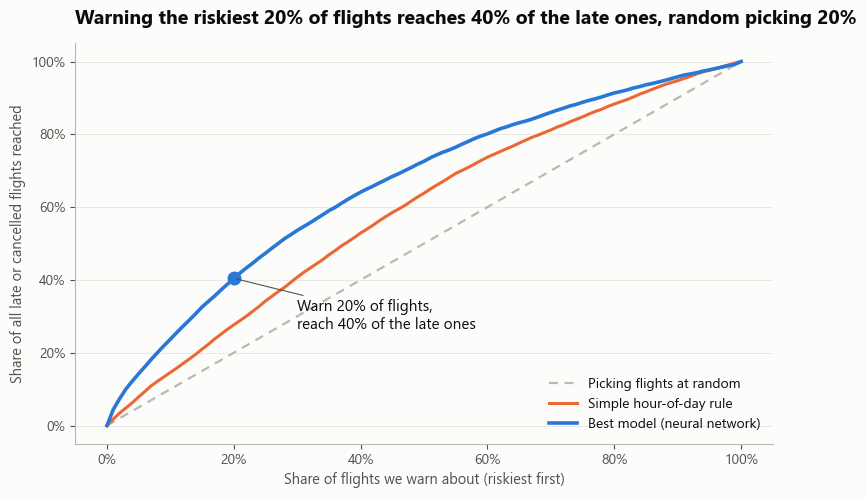

In [22]:
fig, ax = plt.subplots(figsize=(9, 5.2))
share = np.linspace(0, 1, 101)
def gains(risk):
    o = np.argsort(-(risk + np.random.default_rng(common.SEED).random(len(risk)) * 1e-9), kind="stable")
    cum = np.cumsum(y_held[o]) / y_held.sum()
    return np.interp(share, np.arange(1, len(o) + 1) / len(o), cum, left=0)
g_best, g_rule = gains(best_risk), gains(risk_held["hour_rule"])
pd.DataFrame({"share_warned": share, "our_model": g_best, "hour_rule": g_rule, "random_picking": share}).round(4).to_csv(common.REPORTS / "06a_gains_curve.csv", index=False)
ax.plot(share, share, color=viz.GREY, linewidth=1.6, linestyle=(0, (4, 3)), label="Picking flights at random")
ax.plot(share, g_rule, color=viz.ORANGE, linewidth=2.2, label="Simple hour-of-day rule")
ax.plot(share, g_best, color=viz.BLUE, linewidth=2.6, label=f"Best model ({best_model.replace('_', ' ')})")
at20 = g_best[20]
ax.plot(0.2, at20, marker="o", markersize=9, color=viz.BLUE)
ax.annotate(f"Warn 20% of flights,\nreach {at20:.0%} of the late ones", (0.2, at20), xytext=(0.30, at20 - 0.14), fontsize=11, arrowprops=dict(arrowstyle="-", color=viz.INK_2, lw=0.8))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Share of flights we warn about (riskiest first)")
ax.set_ylabel("Share of all late or cancelled flights reached")
ax.legend(loc="lower right")
ax.set_title(f"Warning the riskiest 20% of flights reaches {at20:.0%} of the late ones, random picking {0.2:.0%}")
chart_gains = viz.save_figure(fig, "06a_gains.png")
plt.show()

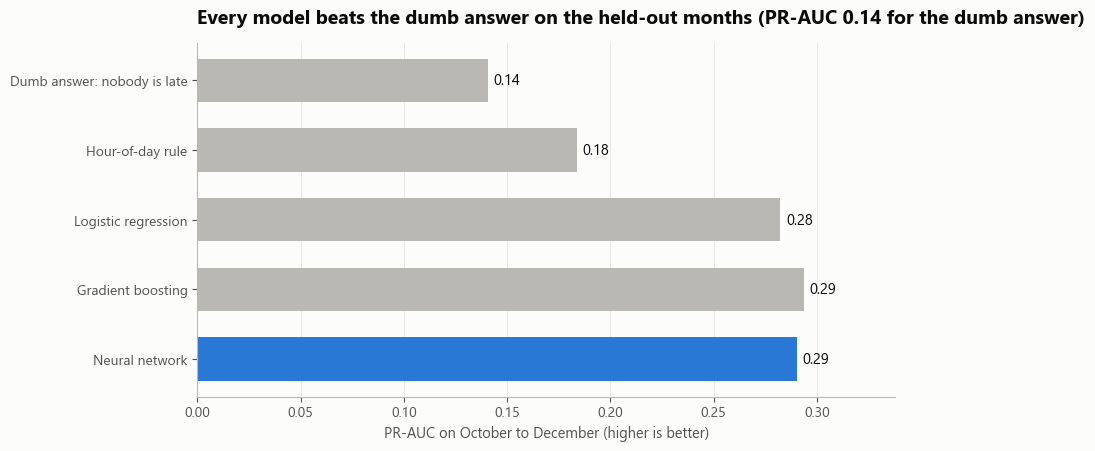

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.6))
names = {"dumb_never_late": "Dumb answer: nobody is late", "hour_rule": "Hour-of-day rule", "logistic_regression": "Logistic regression", "gradient_boosting": "Gradient boosting", "neural_network": "Neural network"}
pr = test_table["pr_auc"].reindex(list(names))
colors = [viz.BLUE if m == best_model else viz.GREY for m in pr.index]
ax.barh([names[m] for m in pr.index][::-1], pr.values[::-1], color=colors[::-1], height=0.62)
for i, v in enumerate(pr.values[::-1]):
    ax.annotate(f"{v:.2f}", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=10.5)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_xlim(0, pr.max() * 1.15)
ax.set_title(f"Every model beats the dumb answer on the held-out months (PR-AUC {pr['dumb_never_late']:.2f} for the dumb answer)")
ax.set_xlabel("PR-AUC on October to December (higher is better)")
chart_scores = viz.save_figure(fig, "06a_model_scores.png")
plt.show()

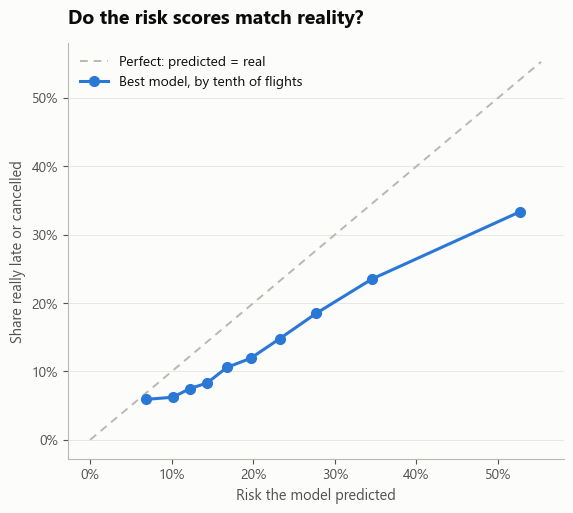

In [24]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
hi = max(calibration["mean_predicted"].max(), calibration["actual_rate"].max()) * 1.05
ax.plot([0, hi], [0, hi], color=viz.GREY, linewidth=1.4, linestyle=(0, (4, 3)), label="Perfect: predicted = real")
ax.plot(calibration["mean_predicted"], calibration["actual_rate"], color=viz.BLUE, linewidth=2.2, marker="o", markersize=7, label="Best model, by tenth of flights")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Risk the model predicted"); ax.set_ylabel("Share really late or cancelled")
ax.legend(loc="upper left")
ax.set_title("Do the risk scores match reality?")
chart_calib = viz.save_figure(fig, "06a_calibration.png")
plt.show()